## Forward Velocity Kinematics (symbolic Jacobian) - Lab 1 R-R-P robot
Given joint velocities $\dot q$, find the tip velocity (twist):

$\xi^0_{0,e} = \begin{bmatrix} \omega \\ v \end{bmatrix} = J^e(q)\,\dot q, \qquad J^e = \begin{bmatrix} J_\omega \\ J_v \end{bmatrix}$

Two ways to get $J_v$ (same answer):
1. **Differentiate FK**: $J_v = \dfrac{\partial p_e}{\partial q}$ (partial derivative of each row of $p_e$ by each joint)
2. **Geometric (column by column)**: $J_{v,j} = (1 - \rho_j)\,\hat z_j + \rho_j\,\hat z_j \times (p_e - p_j)$

$J_\omega$ is the same in both: $J_{\omega,j} = \rho_j\,\hat z_j$. Here $\rho_j = 1$ for a revolute joint and $0$ for a prismatic joint.

In [27]:
import numpy as np
import sympy as sp
from IPython.display import display, Math
from roboticstoolbox import DHRobot, RevoluteMDH, PrismaticMDH
from spatialmath import SE3

def Rx(t): return sp.Matrix([[1, 0, 0, 0], [0, sp.cos(t), -sp.sin(t), 0], [0, sp.sin(t), sp.cos(t), 0], [0, 0, 0, 1]])
def Rz(t): return sp.Matrix([[sp.cos(t), -sp.sin(t), 0, 0], [sp.sin(t), sp.cos(t), 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
def Tx(d): return sp.Matrix([[1, 0, 0, d], [0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
def Tz(d): return sp.Matrix([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 1, d], [0, 0, 0, 1]])

# Modified DH (Craig): T^{i-1}_i = Rx(alpha_{i-1}) Tx(a_{i-1}) Rz(theta_i) Tz(d_i)
def mdh(a, alpha, d, theta):
    return Rx(alpha) * Tx(a) * Rz(theta) * Tz(d)

# display only: sin(q1) -> s_1, cos(q1 + q2) -> c_12
def short(e):
    def sub(f):
        terms = sp.Add.make_args(f.args[0])
        if not all(t.is_Symbol and t.name[0] == 'q' for t in terms):
            return f
        idx = ''.join(sorted((t.name[1:] for t in terms), key=int))
        return sp.Symbol(('s' if f.func == sp.sin else 'c') + '_{' + idx + '}')
    return e.replace(lambda t: t.func in (sp.sin, sp.cos), sub)

def show(lhs, rhs):
    tex = sp.latex(short(rhs)).replace(r'\operatorname{atan}_{2}', r'\operatorname{atan2}')
    display(Math(lhs + ' = ' + tex))

### 0 - Forward kinematics of every frame ${}^{0}T_{i}$
Same MDH table as `fk.ipynb`. Method 2 needs the axis $\hat z_j$ and origin $p_j$ of every joint, so keep every ${}^{0}T_{i}$.

In [28]:
q1, q2, q3 = sp.symbols('q1:4', real=True)
l1, l2, l3, l4 = sp.symbols('l1:5', positive=True)

# MDH table -> (a_{i-1}, alpha_{i-1}, d_i, theta_i)
mdh_table = [
    (0, 0,        l1,      q1),
    (0, sp.pi/2, -l2,      q2 + sp.pi/2),
    (0, sp.pi/2,  q3 + l3, 0),
]
T_tool = Tz(l4)
joint_types = 'RRP'
q = sp.Matrix([q1, q2, q3])

T0 = [sp.eye(4)]                     # T0[i] = {}^0T_i
for row in mdh_table:
    T0.append(sp.simplify(T0[-1] * mdh(*row)))
T0e = sp.simplify(T0[-1] * T_tool)
p = T0e[0:3, 3]

show(r'p_e', p)

<IPython.core.display.Math object>

### Method 1 - Differentiate FK: $J_v = \dfrac{\partial p_e}{\partial q}$
Column $j$ = partial derivative of $p_e = [x, y, z]^T$ by $q_j$.

In [29]:
Jv_diff = sp.simplify(p.jacobian(q))

for i, qi in enumerate(q, start=1):
    show(rf'\frac{{\partial p_e}}{{\partial q_{i}}}', Jv_diff[:, i - 1])
show(r'J_v', Jv_diff)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Note: this only works for the **linear** part. Differentiating the orientation angles gives $\dot r$, and $\omega \ne \dot r$.
So $J_\omega$ always comes from the joint axes (Method 2 below).

### Method 2 - Geometric Jacobian, column by column
For each joint $j$, read from ${}^{0}T_{j}$:
- $\hat z_j$ = joint axis = column 3 of ${}^{0}R_{j}$
- $p_j$ = joint position = column 4 of ${}^{0}T_{j}$

Then

$J_{\omega,j} = \rho_j\,\hat z_j \qquad J_{v,j} = \begin{cases} \hat z_j \times (p_e - p_j) & \text{revolute } (\rho_j = 1) \\ \hat z_j & \text{prismatic } (\rho_j = 0) \end{cases}$

In [30]:
Jv_cols, Jw_cols = [], []
for j, jt in enumerate(joint_types, start=1):
    rho = 1 if jt == 'R' else 0
    z_j = T0[j][0:3, 2]
    p_j = T0[j][0:3, 3]
    Jv_j = sp.simplify((1 - rho) * z_j + rho * z_j.cross(p - p_j))
    Jw_j = rho * z_j

    display(Math(rf'\textbf{{Joint {j}}}\ ({"revolute" if rho else "prismatic"},\ \rho_{j} = {rho}):'))
    show(rf'\hat z_{j}', z_j)
    show(rf'p_{j}', p_j)
    show(rf'J_{{v,{j}}}', Jv_j)
    show(rf'J_{{\omega,{j}}}', Jw_j)
    Jv_cols.append(Jv_j)
    Jw_cols.append(Jw_j)

Jv_geo = sp.Matrix.hstack(*Jv_cols)
Jw = sp.Matrix.hstack(*Jw_cols)
show(r'J_v', Jv_geo)
show(r'J_\omega', Jw)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (7 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Compare the two methods

In [31]:
show(r'J_v^{(1)} - J_v^{(2)}', sp.simplify(Jv_diff - Jv_geo))

<IPython.core.display.Math object>

### Full Jacobian and the FVK equation
$\xi = \begin{bmatrix} \omega \\ v \end{bmatrix} = \begin{bmatrix} J_\omega \\ J_v \end{bmatrix} \dot q$

In [32]:
qd = sp.Matrix([sp.Symbol(rf'\dot{{q}}_{i}', real=True) for i in (1, 2, 3)])
Jv = Jv_geo
J = Jw.col_join(Jv)

show(r'J^e', J)
show(r'\omega', sp.simplify(Jw * qd))
show(r'v', sp.simplify(Jv * qd))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Check with numbers
Compare the symbolic $J$ with RTB `robot_mdh.jacob0(q)`, then check $v$ with a small finite-difference step of FK.
RTB orders the rows as $[v; \omega]$, so swap the halves before comparing.

In [33]:
# edit here: link lengths (m)
vals = {l1: 0.64, l2: 0.2, l3: 0.22, l4: 0.095}

robot_mdh = DHRobot([
    RevoluteMDH(a=0.0, alpha=0.0,     d=vals[l1]),
    RevoluteMDH(a=0.0, alpha=np.pi/2, d=-vals[l2], offset=np.pi/2),
    PrismaticMDH(a=0.0, alpha=np.pi/2, offset=vals[l3]),
], name='my_mdh')
robot_mdh.tool = SE3.Tz(vals[l4])

J_f = sp.lambdify((q1, q2, q3), J.subs(vals), 'numpy')
Jv_diff_f = sp.lambdify((q1, q2, q3), Jv_diff.subs(vals), 'numpy')

# edit here: joint values and joint velocities to test
q_test = np.array([np.pi/6, np.pi/6, 0.18])
qd_test = np.array([0.5, -0.2, 0.05])          # rad/s, rad/s, m/s

J_sym = np.array(J_f(*q_test), dtype=float)
J_rtb = robot_mdh.jacob0(q_test)
J_rtb = np.vstack([J_rtb[3:], J_rtb[:3]])      # [v; w] -> [w; v]
print('J (symbolic, [w; v]) =\n', np.round(J_sym, 4))
print('|J_sym - J_rtb|           =', f'{np.linalg.norm(J_sym - J_rtb):.1e}')
print('|Jv method1 - method2|    =', f'{np.linalg.norm(np.array(Jv_diff_f(*q_test), dtype=float) - J_sym[3:]):.1e}')

twist = J_sym @ qd_test
print('w =', np.round(twist[:3], 4), 'rad/s')
print('v =', np.round(twist[3:], 4), 'm/s')

dt = 1e-6
v_fd = (robot_mdh.fkine(q_test + qd_test * dt).t - robot_mdh.fkine(q_test).t) / dt
print('v (finite difference) =', np.round(v_fd, 4), 'm/s')

J (symbolic, [w; v]) =
 [[ 0.      0.5     0.    ]
 [ 0.     -0.866   0.    ]
 [ 1.      0.      0.    ]
 [-0.3875 -0.2143  0.75  ]
 [ 0.2713 -0.1237  0.433 ]
 [ 0.      0.4287  0.5   ]]
|J_sym - J_rtb|           = 2.5e-16
|Jv method1 - method2|    = 0.0e+00
w = [-0.1     0.1732  0.5   ] rad/s
v = [-0.1134  0.182  -0.0607] m/s
v (finite difference) = [-0.1134  0.182  -0.0607] m/s


### Manipulability
How easily the tip can move in every direction at this pose:

$M = \sqrt{\det\left(J J^T\right)}$

Use the linear part $J_v$ ($3\times3$). The full $6\times3$ $J^e$ always gives $\det(J J^T) = 0$, because 3 joints cannot make 6 independent motions.
For a square $J_v$, $\det(J_v J_v^T) = (\det J_v)^2$, so $M = |\det J_v|$.

In [34]:
det_Jv = sp.factor(sp.simplify(Jv.det()))
show(r'\det J_v', det_Jv)
show(r'M = |\det J_v|', sp.Abs(det_Jv))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

$M = 0$ (singular) when $c_2 = 0$ ($q_2 = \pm 90°$, arm straight up/down) or $L = l_3 + q_3 + l_4 = 0$.

### Manipulability ellipsoid
1. Jacobian $J_v$
2. $A = J_v J_v^T$
3. Eigenvalues $\lambda_i$ and eigenvectors $\vec x_i$ of $A$
4. Ellipsoid: axis $i$ points along $\vec x_i$ with half-length $\sqrt{\lambda_i}$ (tip speed in that direction for $\|\dot q\| = 1$)

Long axis = easy direction, short axis = hard direction, zero axis = singular direction.

q = [0.5236 0.5236 0.18  ] | M = 0.2122 (RTB 0.2122)
   sqrt(lambda_1) = 0.3993 along [ 0.233 -0.922  0.309]
   sqrt(lambda_2) = 0.5218 along [-0.549  0.138  0.824]
   sqrt(lambda_3) = 1.0183 along [-0.802 -0.362 -0.475]
q = [0.5236 1.0472 0.18  ] | M = 0.1225 (RTB 0.1225)
   sqrt(lambda_1) = 0.2292 along [ 0.341 -0.937  0.075]
   sqrt(lambda_2) = 0.5317 along [-0.817 -0.256  0.517]
   sqrt(lambda_3) = 1.0055 along [-0.465 -0.237 -0.853]
q = [0.5236 1.5708 0.18  ] | M = 0.0000 (RTB 0.0000)
   sqrt(lambda_1) = 0.0000 along [-0.5    0.866  0.   ]
   sqrt(lambda_2) = 0.5339 along [ 0.866  0.5   -0.   ]
   sqrt(lambda_3) = 1.0000 along [0. 0. 1.]


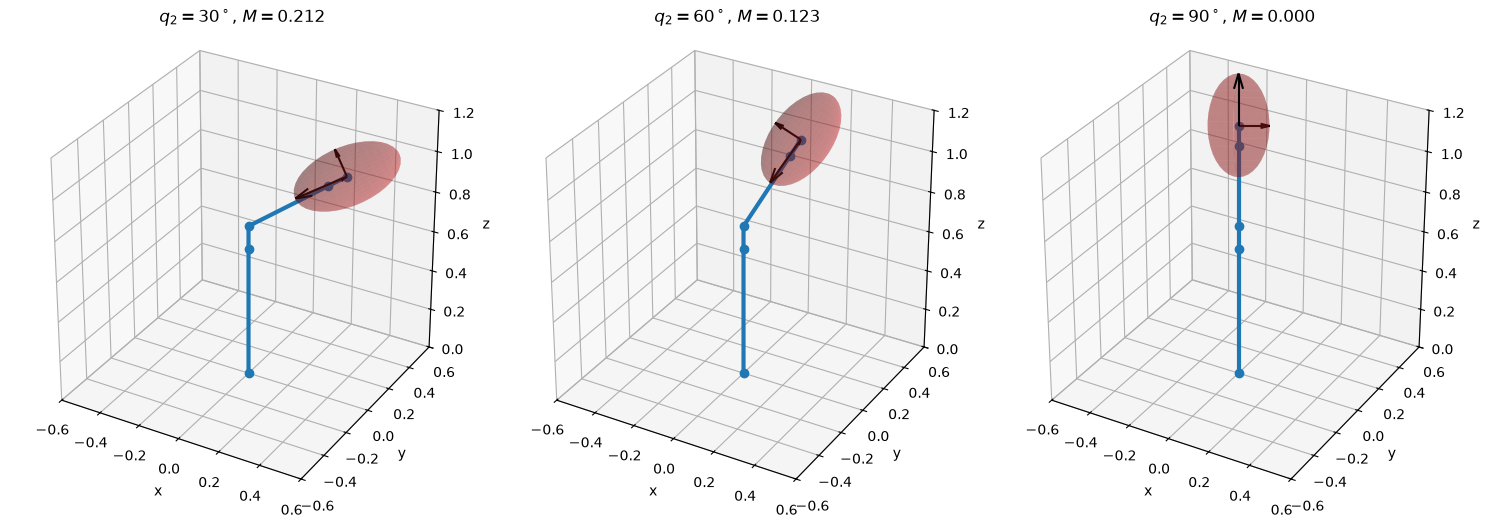

In [35]:
import matplotlib.pyplot as plt

Jv_f = sp.lambdify((q1, q2, q3), Jv.subs(vals), 'numpy')

# edit here: poses to compare (last one is singular, q2 = 90 deg)
poses = [[np.pi/6, np.pi/6, 0.18], [np.pi/6, np.deg2rad(60), 0.18], [np.pi/6, np.pi/2, 0.18]]
scale = 0.25   # draw the ellipsoid smaller so it fits next to the robot (display only)

fig = plt.figure(figsize=(5 * len(poses), 5))
for k, q_test in enumerate(poses, start=1):
    q_test = np.array(q_test)
    Jv_num = np.array(Jv_f(*q_test), dtype=float)
    A = Jv_num @ Jv_num.T
    lam, vec = np.linalg.eigh(A)
    lam = np.clip(lam, 0, None)
    M = np.sqrt(np.linalg.det(A).clip(0))
    M_rtb = robot_mdh.manipulability(q_test, axes='trans')

    print(f'q = {np.round(q_test, 4)} | M = {M:.4f} (RTB {M_rtb:.4f})')
    for i in range(3):
        print(f'   sqrt(lambda_{i+1}) = {np.sqrt(lam[i]):.4f} along {np.round(vec[:, i], 3)}')

    # unit sphere -> ellipsoid: x = V diag(sqrt(lambda)) u
    u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 40), np.linspace(0, np.pi, 20))
    sphere = np.stack([np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)])
    ell = np.einsum('ij,jkl->ikl', scale * vec @ np.diag(np.sqrt(lam)), sphere)
    tip = robot_mdh.fkine(q_test).t
    ax = fig.add_subplot(1, len(poses), k, projection='3d')
    ax.plot_surface(*(ell + tip[:, None, None]), alpha=0.3, color='tab:red')
    for i in range(3):
        a = scale * vec[:, i] * np.sqrt(lam[i])
        ax.quiver(*tip, *a, color='k')
    pts = np.array([T.t for T in robot_mdh.fkine_all(q_test)] + [tip])
    ax.plot(*pts.T, 'o-', lw=3, color='tab:blue')
    ax.set_title(rf'$q_2 = {np.rad2deg(q_test[1]):.0f}^\circ$, $M = {M:.3f}$')
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    ax.set_box_aspect((1, 1, 1))
    ax.set_xlim(-0.6, 0.6); ax.set_ylim(-0.6, 0.6); ax.set_zlim(0, 1.2)
plt.tight_layout()
plt.show()

### Numeric example
Plug a pose and joint speeds into Method 2 column by column, then the twist, then manipulability.

In [36]:
# helpers: plug numbers into a symbolic result and print it rounded
def val(e, subs):
    return float(sp.sympify(e).subs(subs).evalf())
def mat(e, subs, d=4):
    return sp.Matrix(e).subs(subs).evalf().applyfunc(lambda v: sp.Float(round(float(v), d)) if abs(float(v)) > 1e-12 else 0)
def showv(lhs, v, unit=''):
    display(Math(rf'{lhs} = {v:.4f}\ \text{{{unit}}}'))
def showa(lhs, v):
    display(Math(rf'{lhs} = {v:.4f}\ \text{{rad}} = {np.rad2deg(v):.2f}^\circ'))
def showm(lhs, M):
    display(Math(lhs + ' = ' + sp.latex(M)))

# edit here: joint values (deg, deg, m) and joint speeds (rad/s, rad/s, m/s)
q_in = [30, 30, 0.18]
qd_in = [0.5, -0.2, 0.05]

q_val = [np.deg2rad(q_in[0]), np.deg2rad(q_in[1]), q_in[2]]
nums = {**vals, q1: q_val[0], q2: q_val[1], q3: q_val[2]}

showm(r'p_e', mat(p, nums))
for j, jt in enumerate(joint_types, start=1):
    display(Math(rf'\textbf{{Joint {j}}}\ ({"revolute" if jt == "R" else "prismatic"}):'))
    showm(rf'\hat z_{j}', mat(T0[j][0:3, 2], nums))
    showm(rf'p_{j}', mat(T0[j][0:3, 3], nums))
    showm(rf'J_{{v,{j}}}', mat(Jv_cols[j - 1], nums))
    showm(rf'J_{{\omega,{j}}}', mat(Jw_cols[j - 1], nums))

J_num = mat(J, nums)
showm(r'J^e', J_num)
xi = mat(J_num * sp.Matrix(qd_in), {})
showm(r'\xi = \begin{bmatrix} \omega \\ v \end{bmatrix} = J^e \dot q', xi)

# manipulability
Jv_num = mat(Jv, nums)
A_num = mat(Jv_num * Jv_num.T, {})
showm(r'A = J_v J_v^T', A_num)
detA = float(np.linalg.det(np.array(A_num, dtype=float)))
showv(r'\det A', detA)
showv(r'M = \sqrt{\det A}', np.sqrt(max(detA, 0)))
lam, vec = np.linalg.eigh(np.array(A_num, dtype=float))
for i in range(3):
    display(Math(rf'\lambda_{i+1} = {lam[i]:.4f},\ \sqrt{{\lambda_{i+1}}} = {np.sqrt(max(lam[i], 0)):.4f},\ '
                 rf'\vec x_{i+1} = ' + sp.latex(mat(sp.Matrix(vec[:, i]), {}, 3))))
print('RTB manipulability (trans) =', round(robot_mdh.manipulability(q_val, axes='trans'), 4))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (15 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

RTB manipulability (trans) = 0.2122


### Same with Robotics Toolbox
Uses the same `q_in`, `qd_in` as the numeric example. `jacob0` rows are $[v; \omega]$, so swap to get the lecture order $[\omega; v]$.
The cell declares its own MDH robot first, so it can be copied and run on its own (lengths in m: l1 = 0.64, l2 = 0.2, l3 = 0.22, l4 = 0.095).


In [37]:
from roboticstoolbox import DHRobot, RevoluteMDH, PrismaticMDH
from spatialmath import SE3

# 1) declare the robot with MDH (a = a_{i-1}, alpha = alpha_{i-1}, d = d_i, offset added to the joint variable)
robot = DHRobot([
    RevoluteMDH(a=0.0, alpha=0.0,     d=0.64,                    qlim=[-np.pi, np.pi]),   # joint 1 (R)
    RevoluteMDH(a=0.0, alpha=np.pi/2, d=-0.2,  offset=np.pi/2,   qlim=[-np.pi, np.pi]),   # joint 2 (R)
    PrismaticMDH(a=0.0, alpha=np.pi/2, offset=0.22,              qlim=[0.0, 0.3]),        # joint 3 (P), m
], name='my_mdh')
robot.tool = SE3.Tz(0.095)                  # l4: last joint -> tip
print(robot)

# 2) use it
J0 = robot.jacob0(q_val)                # 6x3, rows [v; w]
J_lec = np.vstack([J0[3:], J0[:3]])         # rows [w; v]
print('J^e [w; v] =\n', np.round(J_lec, 4))

xi = J_lec @ np.array(qd_in)
print('w =', np.round(xi[:3], 4), 'rad/s')
print('v =', np.round(xi[3:], 4), 'm/s')

Jv_rtb = J0[:3]                             # linear part only
A = Jv_rtb @ Jv_rtb.T
lam, vec = np.linalg.eigh(A)
print('M (manipulability, axes=trans) =', round(robot.manipulability(q_val, axes='trans'), 4))
print('sqrt(lambda) =', np.round(np.sqrt(lam.clip(0)), 4))
print('eigenvectors (columns) =\n', np.round(vec, 3))

DHRobot: my_mdh, 3 joints (RRP), modified DH parameters
┌──────┬───────┬───────────┬────────────┬─────────┬────────┐
│ aⱼ₋₁ │ ⍺ⱼ₋₁  │    θⱼ     │     dⱼ     │   q⁻    │   q⁺   │
├──────┼───────┼───────────┼────────────┼─────────┼────────┤
│  0.0 │  0.0° │        q1 │       0.64 │ -180.0° │ 180.0° │
│  0.0 │ 90.0° │  q2 + 90° │       -0.2 │ -180.0° │ 180.0° │
│  0.0 │ 90.0° │      0.0° │  q3 + 0.22 │       0 │    0.3 │
└──────┴───────┴───────────┴────────────┴─────────┴────────┘

┌──────┬───────────────────────────────────────┐
│ tool │ t = 0, 0, 0.095; rpy/xyz = 0°, 0°, 0° │
└──────┴───────────────────────────────────────┘

J^e [w; v] =
 [[-0.      0.5     0.    ]
 [-0.     -0.866   0.    ]
 [ 1.      0.      0.    ]
 [-0.3875 -0.2143  0.75  ]
 [ 0.2713 -0.1237  0.433 ]
 [ 0.      0.4287  0.5   ]]
w = [-0.1     0.1732  0.5   ] rad/s
v = [-0.1134  0.182  -0.0607] m/s
M (manipulability, axes=trans) = 0.2122
sqrt(lambda) = [0.3993 0.5218 1.0183]
eigenvectors (columns) =
 [[ 0.233 -0.549 -